# Bank Personal Loan Prediction: classifier benchmark (with and without SMOTE)

**Goal:** predict whether a bank customer accepts a personal loan (`Personal Loan`), and measure whether SMOTE helps on this imbalanced dataset (~9.6% positives).

**What changed compared with the first version of this notebook**
- Metrics now include **precision, recall and F1 for the loan class** (accuracy alone is misleading: predicting "no loan" for everyone already scores ~90%).
- A **majority-class baseline** is added for reference.
- **Scaling is done inside a pipeline** (KNN, SVM and Naive Bayes variants need it), so nothing leaks from the test set.
- **SMOTE is applied to the training data only** (inside the pipeline, also within each cross-validation fold), and the test set stays untouched.
- Both setups use the **same train/test split**, so the comparison is fair.
- Fixed: undefined `x_train` in the clustering cells, deprecated `base_estimator`, AdaBoost settings that could not learn (`learning_rate=0.001`, 10 trees), `ID` and `ZIP Code` used as features.
- Model selection uses **cross-validated F1 on the training set**, not the test set.

**To run:** place `Bank_Personal_Loan_Modelling.xlsx` next to this notebook (in Colab: upload it, or set `DATA_PATH = '/content/Bank_Personal_Loan_Modelling.xlsx'`), then *Run all*.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, classification_report, ConfusionMatrixDisplay)
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, dendrogram

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline   # works with or without a sampler step

SEED = 0
DATA_PATH = 'Bank_Personal_Loan_Modelling.xlsx'   # Colab: '/content/Bank_Personal_Loan_Modelling.xlsx'
sns.set_style('darkgrid')

## 1. Load and clean the data

In [2]:
df = pd.read_excel(DATA_PATH, sheet_name='Data')
print(df.shape)
df.info()
df.head()

(5000, 14)
<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ID                  5000 non-null   int64  
 1   Age                 5000 non-null   int64  
 2   Experience          5000 non-null   int64  
 3   Income              5000 non-null   int64  
 4   ZIP Code            5000 non-null   int64  
 5   Family              5000 non-null   int64  
 6   CCAvg               5000 non-null   float64
 7   Education           5000 non-null   int64  
 8   Mortgage            5000 non-null   int64  
 9   Personal Loan       5000 non-null   int64  
 10  Securities Account  5000 non-null   int64  
 11  CD Account          5000 non-null   int64  
 12  Online              5000 non-null   int64  
 13  CreditCard          5000 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 547.0 KB


,ID,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
0,1,25,1,49,91107,4,1.6,1,0,0,1,0,0,0
1,2,45,19,34,90089,3,1.5,1,0,0,1,0,0,0
2,3,39,15,11,94720,1,1.0,1,0,0,0,0,0,0
3,4,35,9,100,94112,1,2.7,2,0,0,0,0,0,0
4,5,35,8,45,91330,4,1.0,2,0,0,0,0,0,1


In [3]:
n0 = len(df)

# 1) ZIP codes below 20000 are noise (invalid California ZIPs)
bad_zip = (df['ZIP Code'] < 20000).sum()
df = df[df['ZIP Code'] >= 20000]

# 2) Negative 'Experience' values are data-entry errors: take the absolute value
neg_exp = (df['Experience'] < 0).sum()
df['Experience'] = df['Experience'].abs()

# 3) Remove extreme 'Mortgage' outliers (z-score > 3)
z = stats.zscore(df['Mortgage'])
n_out = int((z > 3).sum())
df = df[z <= 3]

# 4) Duplicates and missing values
n_dup = int(df.duplicated().sum())
n_na = int(df.isnull().sum().sum())

# 5) Units: CCAvg is monthly, Income is annual -> make both annual
df['CCAvg'] = df['CCAvg'] * 12

df = df.reset_index(drop=True)
print(f'rows before: {n0} | invalid ZIP removed: {bad_zip} | negative Experience fixed: {neg_exp} | '
      f'Mortgage outliers removed: {n_out} | duplicates: {n_dup} | missing values: {n_na} | rows after: {len(df)}')

rows before: 5000 | invalid ZIP removed: 1 | negative Experience fixed: 52 | Mortgage outliers removed: 105 | duplicates: 0 | missing values: 0 | rows after: 4894


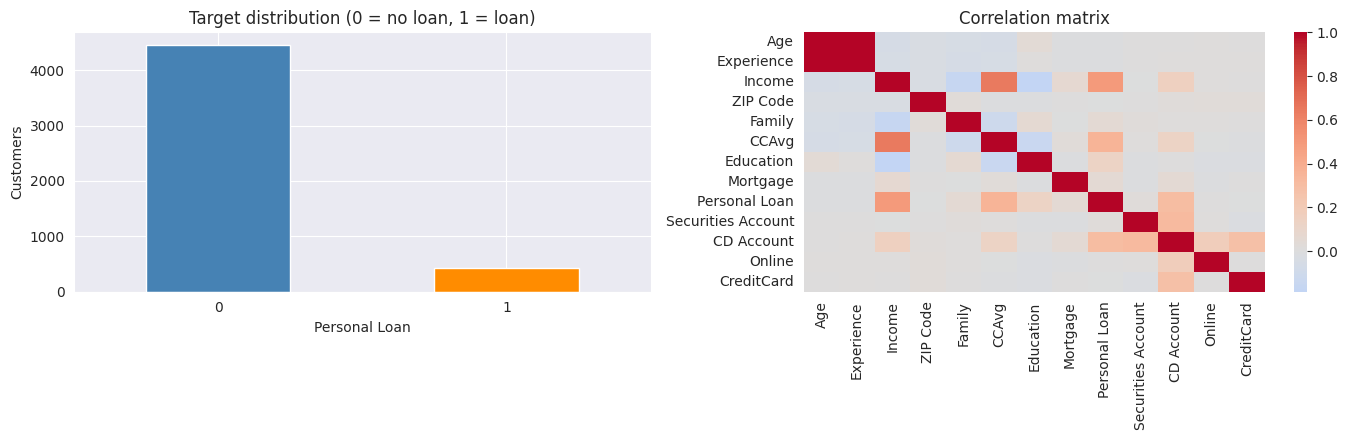

Share of customers who took the loan: 8.8%


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
df['Personal Loan'].value_counts().plot(kind='bar', ax=ax[0], color=['steelblue', 'darkorange'])
ax[0].set_title('Target distribution (0 = no loan, 1 = loan)')
ax[0].set_xlabel('Personal Loan'); ax[0].set_ylabel('Customers'); ax[0].tick_params(axis='x', rotation=0)
sns.heatmap(df.drop(columns=['ID']).corr(), cmap='coolwarm', center=0, ax=ax[1])
ax[1].set_title('Correlation matrix')
plt.tight_layout(); plt.show()

print('Share of customers who took the loan: {:.1%}'.format(df['Personal Loan'].mean()))

## 2. Train/test split

`ID` is just a row number and `ZIP Code` is a numeric code with no meaningful order, so both are dropped as features. The split is stratified so the class ratio is the same in train and test.

In [5]:
TARGET = 'Personal Loan'
X = df.drop(columns=[TARGET, 'ID', 'ZIP Code'])
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=SEED, stratify=y)

print('train:', X_train.shape, '| test:', X_test.shape)
print('loan rate  train: {:.1%} | test: {:.1%}'.format(y_train.mean(), y_test.mean()))
print('positives in test set:', int(y_test.sum()))

train: (3425, 11) | test: (1469, 11)
loan rate  train: 8.8% | test: 8.8%
positives in test set: 130


## 3. Experiment setup

- **Baseline:** always predict "no loan". Any model must beat this on recall/F1 of the loan class, not on accuracy.
- **Models:** KNN, SVM, Naive Bayes, AdaBoost (decision stumps), and two hybrids: AdaBoost + SVM and AdaBoost + Naive Bayes.
- **Two setups, same split:** (A) no resampling, (B) SMOTE on the training data only.
- **Reported:** test-set metrics for the loan class, plus 5-fold cross-validated F1/recall on the training set (mean ± std), which is more stable than a single test split with only a few hundred positives.

In [6]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def get_models(k):
    """name -> (scaler, estimator). Fresh objects on every call."""
    return {
        'KNN':               (StandardScaler(), KNeighborsClassifier(n_neighbors=k)),
        'SVM (RBF)':         (StandardScaler(), SVC(kernel='rbf', C=1.0, random_state=SEED)),
        'Naive Bayes':       (StandardScaler(), GaussianNB()),
        'AdaBoost':          ('passthrough',    AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1),
                                                                   n_estimators=200, learning_rate=0.5, random_state=SEED)),
        'AdaBoost + SVM':    (StandardScaler(), AdaBoostClassifier(estimator=SVC(kernel='rbf', C=1.0),
                                                                   n_estimators=10, random_state=SEED)),
        # MultinomialNB needs non-negative inputs, hence MinMaxScaler
        'AdaBoost + NB':     (MinMaxScaler(),   AdaBoostClassifier(estimator=MultinomialNB(),
                                                                   n_estimators=10, random_state=SEED)),
    }

def make_pipe(name, k, use_smote):
    scaler, est = get_models(k)[name]
    steps = [('scale', scaler)]
    if use_smote:
        steps.append(('smote', SMOTE(random_state=SEED)))   # only ever fitted on training data
    steps.append(('clf', est))
    return Pipeline(steps)

def tune_k(use_smote, grid=(3, 5, 7, 9, 11, 15, 21)):
    pipe = make_pipe('KNN', 5, use_smote)
    gs = GridSearchCV(pipe, {'clf__n_neighbors': list(grid)}, scoring='f1', cv=skf, n_jobs=-1)
    gs.fit(X_train, y_train)
    return gs.best_params_['clf__n_neighbors'], gs.best_score_

def positive_scores(pipe, X_):
    for fn in ('predict_proba', 'decision_function'):
        try:
            out = getattr(pipe, fn)(X_)
            return out[:, 1] if out.ndim == 2 else out
        except Exception:
            continue
    return None

def evaluate(pipe, label, use_smote):
    cv = cross_validate(pipe, X_train, y_train, cv=skf, scoring=['f1', 'recall', 'precision'], n_jobs=-1)
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    s = positive_scores(pipe, X_test)
    return {
        'Model': label, 'SMOTE': use_smote,
        'Accuracy':  accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred, zero_division=0),
        'Recall':    recall_score(y_test, pred),
        'F1':        f1_score(y_test, pred),
        'ROC-AUC':   roc_auc_score(y_test, s) if s is not None else np.nan,
        'CV F1':     cv['test_f1'].mean(),  'CV F1 std': cv['test_f1'].std(),
        'CV Recall': cv['test_recall'].mean(),
    }, pipe

# Baseline: majority class
base = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
bp = base.predict(X_test)
print('Majority-class baseline -> accuracy {:.3f} | recall {:.3f} | F1 {:.3f}'.format(
    accuracy_score(y_test, bp), recall_score(y_test, bp), f1_score(y_test, bp, zero_division=0)))

Majority-class baseline -> accuracy 0.912 | recall 0.000 | F1 0.000


In [7]:
rows, fitted = [], {}
best_k = {}
for use_smote in (False, True):
    k, cv_f1 = tune_k(use_smote)
    best_k[use_smote] = k
    print(f'SMOTE={use_smote}: best k for KNN = {k} (CV F1 = {cv_f1:.3f})')
    for name in get_models(k):
        row, pipe = evaluate(make_pipe(name, k, use_smote), name, use_smote)
        rows.append(row); fitted[(name, use_smote)] = pipe

results = pd.DataFrame(rows)
results['Setup'] = results['SMOTE'].map({False: 'No SMOTE', True: 'SMOTE'})
cols = ['Model', 'Setup', 'Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC', 'CV F1', 'CV F1 std', 'CV Recall']
results[cols].round(3)

SMOTE=False: best k for KNN = 3 (CV F1 = 0.742)


SMOTE=True: best k for KNN = 3 (CV F1 = 0.746)


,Model,Setup,Accuracy,Precision,Recall,F1,ROC-AUC,CV F1,CV F1 std,CV Recall
0,KNN,No SMOTE,0.963,0.952,0.615,0.748,0.904,0.742,0.046,0.630
1,SVM (RBF),No SMOTE,0.973,0.969,0.723,0.828,0.985,0.820,0.030,0.719
2,Naive Bayes,No SMOTE,0.884,0.390,0.562,0.461,0.924,0.496,0.040,0.591
3,AdaBoost,No SMOTE,0.969,0.947,0.692,0.800,0.982,0.795,0.046,0.697
4,AdaBoost + SVM,No SMOTE,0.912,0.000,0.000,0.000,0.500,0.000,0.000,0.000
5,AdaBoost + NB,No SMOTE,0.928,0.613,0.500,0.551,0.887,0.265,0.217,0.280
6,KNN,SMOTE,0.963,0.768,0.838,0.801,0.924,0.746,0.038,0.818
7,SVM (RBF),SMOTE,0.971,0.801,0.900,0.848,0.985,0.795,0.027,0.861
8,Naive Bayes,SMOTE,0.873,0.392,0.785,0.523,0.929,0.559,0.007,0.822
9,AdaBoost,SMOTE,0.879,0.417,0.931,0.576,0.972,0.615,0.021,0.940


### Effect of SMOTE (test set, loan class)

,Recall (No SMOTE),Recall (SMOTE),F1 (No SMOTE),F1 (SMOTE),Recall change,F1 change
Model,,,,,,
AdaBoost,0.692,0.931,0.800,0.576,0.238,-0.224
AdaBoost + NB,0.500,0.746,0.551,0.393,0.246,-0.158
AdaBoost + SVM,0.000,0.915,0.000,0.488,0.915,0.488
KNN,0.615,0.838,0.748,0.801,0.223,0.054
Naive Bayes,0.562,0.785,0.461,0.523,0.223,0.063
SVM (RBF),0.723,0.900,0.828,0.848,0.177,0.020


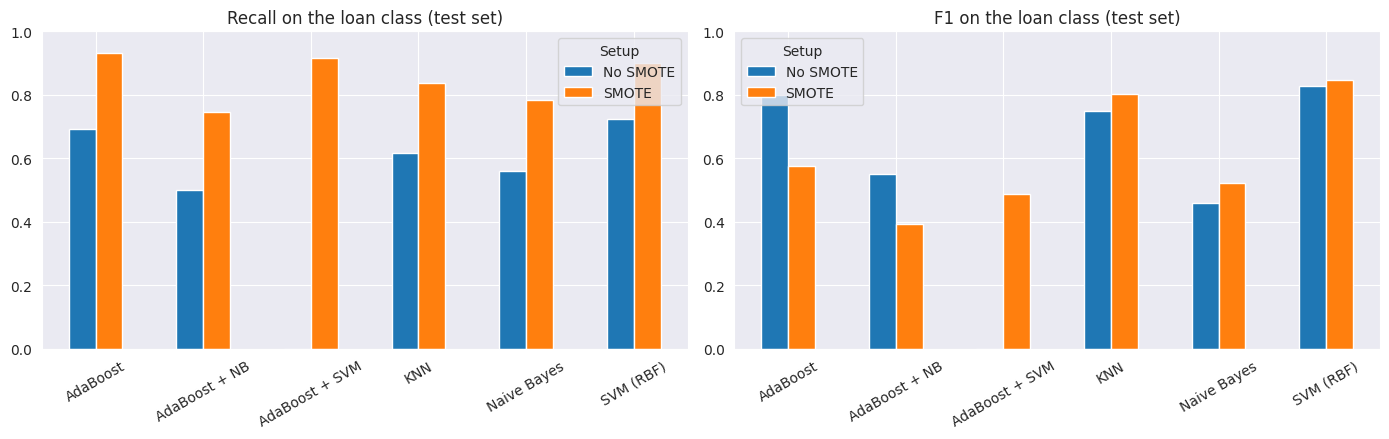

In [8]:
cmp = results.pivot(index='Model', columns='Setup', values=['Recall', 'F1'])
cmp.columns = [f'{m} ({s})' for m, s in cmp.columns]
cmp['Recall change'] = cmp['Recall (SMOTE)'] - cmp['Recall (No SMOTE)']
cmp['F1 change']     = cmp['F1 (SMOTE)'] - cmp['F1 (No SMOTE)']
display(cmp.round(3))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for a, metric in zip(ax, ['Recall', 'F1']):
    results.pivot(index='Model', columns='Setup', values=metric)[['No SMOTE', 'SMOTE']].plot(kind='bar', ax=a)
    a.set_title(f'{metric} on the loan class (test set)'); a.set_ylim(0, 1); a.set_xlabel('')
    a.tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()

### Best model per setup (selected by cross-validated F1 on the training set)

No SMOTE -> best model: SVM (RBF)
              precision    recall  f1-score   support

     No loan      0.974     0.998     0.986      1339
        Loan      0.969     0.723     0.828       130

    accuracy                          0.973      1469
   macro avg      0.971     0.860     0.907      1469
weighted avg      0.973     0.973     0.972      1469



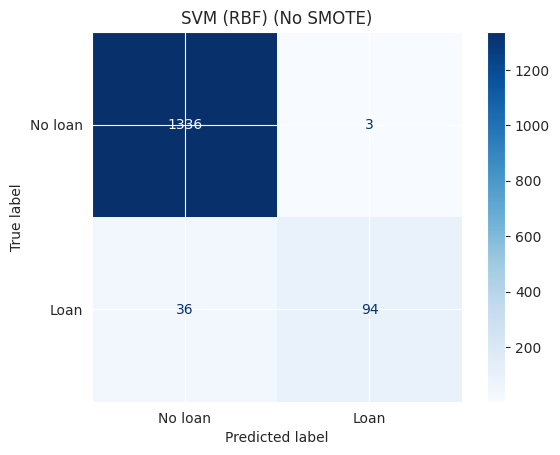

SMOTE -> best model: SVM (RBF)
              precision    recall  f1-score   support

     No loan      0.990     0.978     0.984      1339
        Loan      0.801     0.900     0.848       130

    accuracy                          0.971      1469
   macro avg      0.896     0.939     0.916      1469
weighted avg      0.973     0.971     0.972      1469



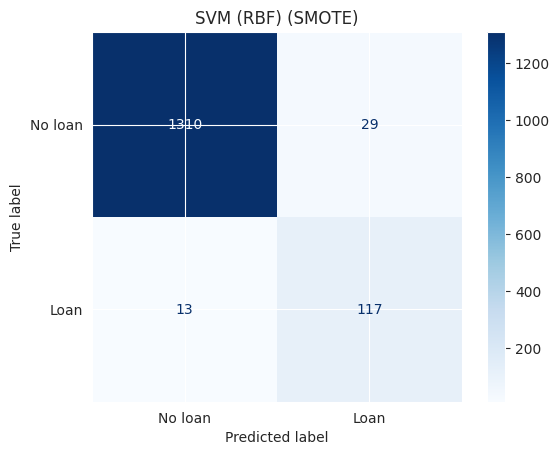

In [9]:
for use_smote in (False, True):
    sub = results[results['SMOTE'] == use_smote]
    best = sub.loc[sub['CV F1'].idxmax(), 'Model']
    pipe = fitted[(best, use_smote)]
    pred = pipe.predict(X_test)
    print('=' * 70)
    print(f'{"SMOTE" if use_smote else "No SMOTE"} -> best model: {best}')
    print(classification_report(y_test, pred, target_names=['No loan', 'Loan'], digits=3))
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=['No loan', 'Loan'], cmap='Blues')
    plt.title(f'{best} ({"SMOTE" if use_smote else "No SMOTE"})'); plt.show()

## 4. Exploratory clustering (unsupervised, optional)

Run on the scaled training features, without the target.

Silhouette by k: {2: np.float64(0.141), 3: np.float64(0.143), 4: np.float64(0.163), 5: np.float64(0.174), 6: np.float64(0.143), 7: np.float64(0.14), 8: np.float64(0.159)}
Best number of clusters for KMeans: 5


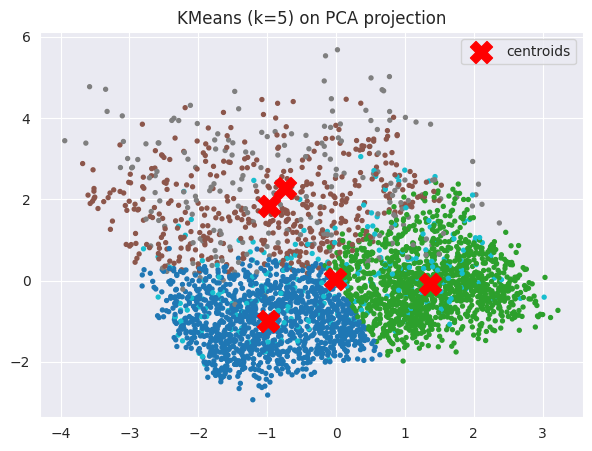

Loan rate per cluster:
0    0.030
1    0.027
2    0.308
3    0.425
4    0.020
dtype: float64


In [10]:
Xs = StandardScaler().fit_transform(X_train)

ks = range(2, 9)
sil = []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Xs)
    sil.append(silhouette_score(Xs, km.labels_))
best_k_km = list(ks)[int(np.argmax(sil))]
print('Silhouette by k:', dict(zip(ks, np.round(sil, 3))))
print('Best number of clusters for KMeans:', best_k_km)

km = KMeans(n_clusters=best_k_km, n_init=10, random_state=SEED).fit(Xs)
p = PCA(n_components=2, random_state=SEED).fit(Xs)
Z, C_ = p.transform(Xs), p.transform(km.cluster_centers_)
plt.figure(figsize=(7, 5))
plt.scatter(Z[:, 0], Z[:, 1], c=km.labels_, s=8, cmap='tab10')
plt.scatter(C_[:, 0], C_[:, 1], s=250, c='red', marker='X', label='centroids')
plt.title(f'KMeans (k={best_k_km}) on PCA projection'); plt.legend(); plt.show()

print('Loan rate per cluster:')
print(pd.Series(y_train.values).groupby(km.labels_).mean().round(3))

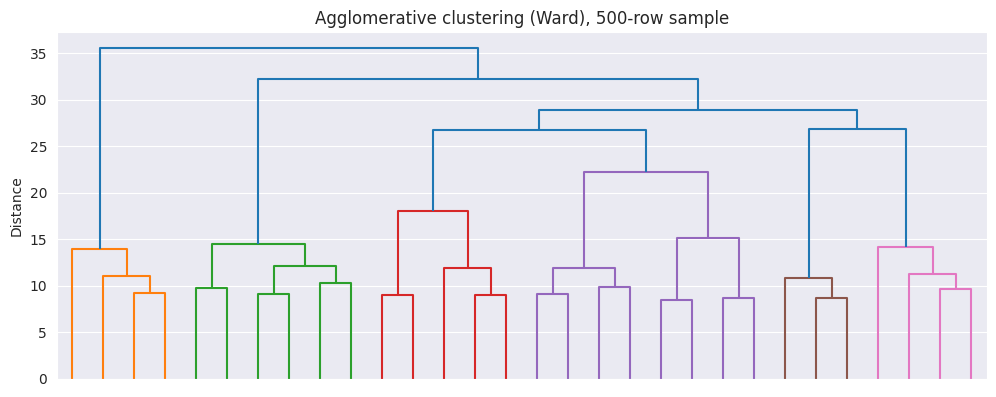

In [11]:
# Hierarchical clustering on a random sample (a full dendrogram of every row is unreadable)
rng = np.random.RandomState(SEED)
idx = rng.choice(len(Xs), size=500, replace=False)
plt.figure(figsize=(12, 4.5))
dendrogram(linkage(Xs[idx], method='ward'), truncate_mode='lastp', p=30, no_labels=True)
plt.title('Agglomerative clustering (Ward), 500-row sample'); plt.ylabel('Distance'); plt.show()

In [12]:
results[cols].round(4).to_csv('results.csv', index=False)
print('Saved results.csv')

Saved results.csv
